<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

# Empirical Parameters Calibration for Exponential Clock distrirbution



## Folder placement

- **Current location**: `analyses/calibration/clock/exponential/`


## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: Bluesky firehose
- **Time range**: 2025-05-01
- **Access / documentation link**: Data collection was done with [`osome-iu/osome-bluesky-streamer`](https://github.com/osome-iu/osome-bluesky-streamer), an archive can be requested by contacting [OSoMe IU](https://osome.iu.edu/resources/data-resources).
- **Raw files / tables used**: `2025-05-01.json.gz`
- **Preprocessing steps**: 
    1. Read `commit_time_str` from each event in the firehose
    2. Convert from microseconds to milliseconds and cast to `int`
    3. Store with `action`, `type`, and `author`

## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: `ExponentialClockManager`
- **What it adds**: Derives the parameters for the exponential distribution based on number of users
- **Code location**: `libs/simsom/clock_manager.py`
- **Design rationale**: Experiments show that distribution of deltas between timestamps follows an exponential distribution, which matches theoretical expectations based on user behavior. Using a model that centrally generates timestamps is a simple way to create realistic synthetic data.


## 2b) References & provenance

Make the calibration traceable to specific code and discussion history. Complete one or more of items below.



In [ ]:
import gzip
import json
import logging

from tqdm import tqdm
from datetime import datetime

def get_timestamps(path):
    dates = []
    actions = []
    types = []
    dids = []
    with gzip.open(path, "rt") as f:
        for line in tqdm(f):
            try:
                event = json.loads(line)

                ts = datetime.strptime(event["commit_time_str"], "%Y-%m-%dT%H:%M:%S.%fZ")
                dates.append(int(ts.timestamp() * 1000))

                actions.append(event["action"])
                types.append(event["type"])
                dids.append(event["author"])

            except json.JSONDecodeError as e:
                logging.debug(f"Error in {path}:\n{e}")

    return dates, actions, types, dids

path = "YOUR_PATH_HERE/2025-05-01.json.gz"

timestamps, actions, types, dids = get_timestamps(path)

with gzip.open("timestamps_bsky_users.csv.gz", "wt") as f:
    f.write(f"timestamp,action,type,did\n")
    for ts, action, type, did in zip(timestamps, actions, types, dids):
        f.write(f"{ts},{action},{type},{did}\n")

In [ ]:
import pandas as pd

df = pd.read_csv("timestamps_bsky_users.csv.gz")
df = df[(df["type"] == "app.bsky.feed.post") | (df["type"] == "app.bsky.feed.repost")]
df

,timestamp,action,type,did
10382824,1746071999848,create,app.bsky.feed.repost,did:plc:nerqo7p3r6wzgysnymtipzv3
31505556,1746071999877,create,app.bsky.feed.repost,did:plc:npbzttlufanky5p3pwjjqbge
34148192,1746071999889,create,app.bsky.feed.post,did:plc:olol7qkyezzrxcynunk33d7g
491735,1746071999921,create,app.bsky.feed.repost,did:plc:feayemc6lirej5w4r67uqyvq
11528560,1746071999923,create,app.bsky.feed.post,did:plc:bmadyvkfnffvw72yi3hxtaaz
...,...,...,...,...
20259902,1746158399794,create,app.bsky.feed.post,did:plc:3jqlhhab5xmpx3ijukjzvdrs
17260963,1746158399833,create,app.bsky.feed.post,did:plc:7g7izbxtrgjywsqkeuwucrms
494668,1746158399833,delete,app.bsky.feed.post,did:plc:kkjc3etgu76vk42abnmbnyly
20861898,1746158399834,create,app.bsky.feed.post,did:plc:jupkjv3ehcgiy3wtglmdbdui


## 3) Analysis / calibration method

- **Features extracted**: Per-user posting timestamps from firehose events, converted to ms; inter-event deltas per user; per-day counts aggregated into deltas distributions; per-sample total posting rate sums.
- **Estimation / fitting**: For sampled user counts, compute delta distributions and fit exponential CCDF parameter `b` via `curve_fit`; fit linear relationship between user count and sum of post rates with `linregress`.
- **Validation**: Scatter plots of user count vs rate sums and fitted parameters; CCDF plots across user-count samples.


In [ ]:
import numpy as np
import random

all_users = list(set(df["did"]))
all_deltas = []
all_rate_sums = []
user_counts = sorted([int(random.random() * len(all_users)) for _ in range(20)] + [1000, 2500, 5000, 7500, 10000, 25000, 50000, 75000, 100000])

for user_count in user_counts:
    random.shuffle(all_users)
    subset = set(all_users[:user_count])

    sub_df = df[df["did"].isin(subset)]    

    timestamps = np.array(sub_df["timestamp"])
    deltas = np.diff(timestamps)
    deltas = deltas[(deltas >= 0) & (deltas < 86400000)]
    deltas[deltas == 0] += 1

    post_rates = np.array(sub_df["did"].value_counts()) / 86400000

    all_deltas.append(deltas)
    all_rate_sums.append(np.sum(post_rates))

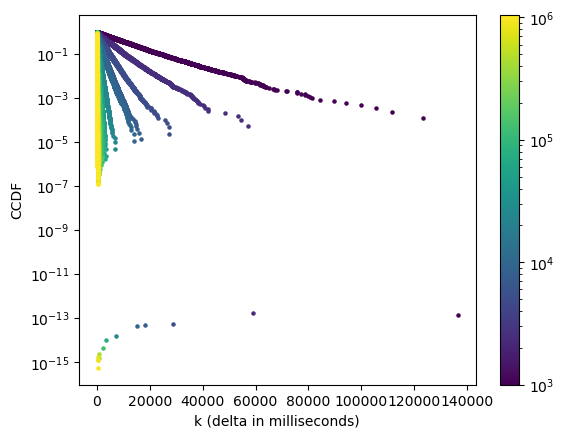

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from collections import Counter

cmap = cm.viridis
norm = mcolors.LogNorm(vmin=1000, vmax=len(all_users))

for deltas, user_count in zip(all_deltas, user_counts):
    counts = Counter(deltas)

    X = np.sort(np.array(list(counts.keys())))

    max_y = sum(counts.values())
    y = [counts[c] / max_y for c in X]

    y = 1 - np.cumsum(y)

    plt.scatter(X, y, s=5, color=cmap(norm(user_count)))

scalarmappaple = cm.ScalarMappable(norm=norm, cmap=cmap)
scalarmappaple.set_array(user_counts)
plt.colorbar(scalarmappaple, ax=plt.gca())

plt.xlabel("k (delta in milliseconds)")
plt.ylabel("CCDF")
#plt.loglog()
plt.yscale("log")
plt.show()

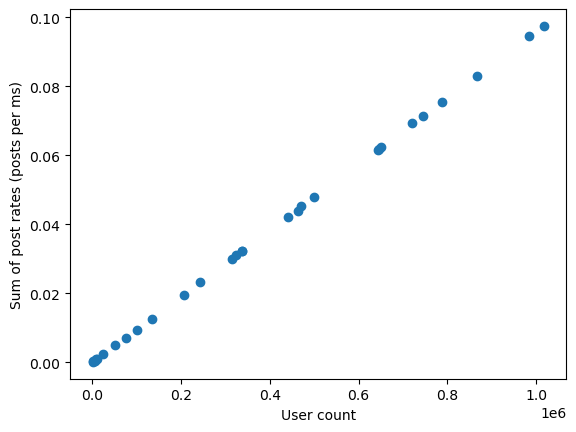

In [ ]:
plt.scatter(user_counts, all_rate_sums)
plt.xlabel("User count")
plt.ylabel("Sum of post rates (posts per ms)")
plt.show()

In [ ]:
from scipy.optimize import curve_fit

def exp_ccdf_log(x, b):
    return -b * x

def exp_ccdf(x, b):
    return np.exp(-b * x)

all_b = []
for deltas in all_deltas:
    counts = Counter(deltas)

    X = np.array(list(counts.keys()))

    max_y = sum(counts.values())
    y = np.array([counts[c] / max_y for c in X])

    b, pcov = curve_fit(exp_ccdf_log, X, np.log(y), maxfev=2000)

    all_b.append(b)

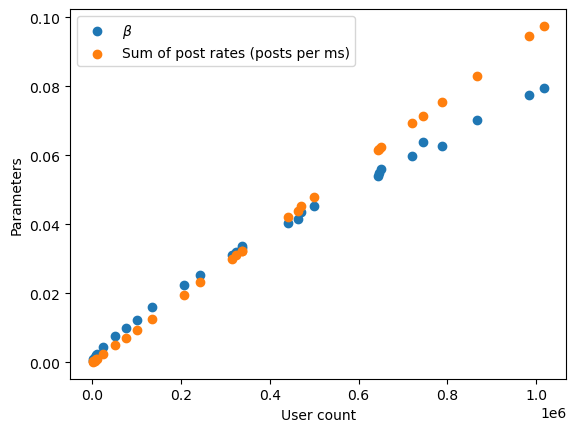

In [ ]:
user_counts = np.array(user_counts)

plt.scatter(user_counts, all_b, label=r"$\beta$")
plt.scatter(user_counts, all_rate_sums, label="Sum of post rates (posts per ms)")
plt.xlabel("User count")
plt.ylabel("Parameters")
plt.legend()
plt.show()

## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure `path = "YOUR_PATH_HERE/2025-05-01.json.gz"` is set correctly
2. Run this notebook top-to-bottom to reproduce the plots and fitted parameters.


## 4) Results

Summarize the outcome and attach key plots/tables.

Along with the plots, the following two values are used as the parameters for `ExponentialClockManager`.

In [ ]:
from scipy.stats import linregress

result = linregress(user_counts, all_rate_sums)
print(result.slope)
print(result.intercept)

9.586385781407468e-08
3.907543315063294e-05


## 5) Change log

Record updates so future changes are traceable.

- `2026-03-04`: Initial assembly of the report.
